In [3]:
import requests
import pandas as pd
import time

In [2]:
url = "https://api.openalex.org/works"

params = {
    "search": "machine learning",
    "filter": "has_abstract:true",
    "per_page": 3,
    "select": "id,doi,title,publication_year,abstract_inverted_index"
}

response = requests.get(url, params=params, timeout=30)

print("HTTP status:", response.status_code)

if response.status_code == 200:
    data = response.json()

    print("Number of results:", len(data["results"]))

    for paper in data["results"]:
        print("\nTitle:", paper.get("title"))
        print("Year:", paper.get("publication_year"))
        print("Abstract available:", bool(paper.get("abstract_inverted_index")))
else:
    print(response.text[:500])

HTTP status: 200
Number of results: 3

Title: Machine learning and deep learning
Year: 2021
Abstract available: True

Title: Machine Learning
Year: 2012
Abstract available: True

Title: Machine Learning
Year: 2021
Abstract available: True


In [3]:
def reconstruct_abstract(inverted_index):
    if not inverted_index:
        return ""

    positions = {}

    for word, indexes in inverted_index.items():
        for index in indexes:
            positions[index] = word

    return " ".join(
        positions[index]
        for index in sorted(positions)
    )

In [4]:
example = {
    "Deep": [0],
    "learning": [1],
    "improves": [2],
    "classification": [3]
}

print(reconstruct_abstract(example))

Deep learning improves classification


In [5]:
import requests
import pandas as pd
import time

BASE_URL = "https://api.openalex.org/works"

def collect_category(search_terms, label, target=400):
    records = []
    seen_ids = set()

    for term in search_terms:
        if len(records) >= target:
            break

        print(f"Searching {label}: {term}")

        for page in range(1, 3):
            if len(records) >= target:
                break

            params = {
                "search": term,
                "filter": "has_abstract:true",
                "per_page": 100,
                "page": page,
                "select": (
                    "id,doi,title,publication_year,"
                    "abstract_inverted_index"
                )
            }

            response = requests.get(
                BASE_URL,
                params=params,
                timeout=30
            )
            response.raise_for_status()

            papers = response.json()["results"]

            for paper in papers:
                paper_id = paper.get("id")

                if not paper_id or paper_id in seen_ids:
                    continue

                abstract = reconstruct_abstract(
                    paper.get("abstract_inverted_index")
                )

                title = paper.get("title") or ""

                # Ignore empty or unusably short records.
                if len(abstract.split()) < 30:
                    continue

                seen_ids.add(paper_id)

                records.append({
                    "openalex_id": paper_id,
                    "doi": paper.get("doi"),
                    "title": title,
                    "abstract": abstract,
                    "publication_year": paper.get(
                        "publication_year"
                    ),
                    "label": label,
                    "search_term": term,
                    "label_review": "pending"
                })

                if len(records) >= target:
                    break

            time.sleep(0.2)

    result = pd.DataFrame(records)

    print(f"Collected {len(result)} records for {label}")
    return result

In [6]:
science_terms = [
    "artificial intelligence",
    "physics experimental research",
    "molecular biology",
    "chemical engineering",
    "climate science"
]

business_terms = [
    "corporate finance",
    "marketing consumer behavior",
    "entrepreneurship",
    "accounting research",
    "business management"
]

social_science_terms = [
    "sociology social inequality",
    "educational research",
    "political science",
    "social policy",
    "human behavior society"
]

In [7]:
science_df = collect_category(
    science_terms,
    label="Science",
    target=400
)

business_df = collect_category(
    business_terms,
    label="Business",
    target=400
)

social_df = collect_category(
    social_science_terms,
    label="Social Science",
    target=400
)

Searching Science: artificial intelligence
Searching Science: physics experimental research
Searching Science: molecular biology
Collected 400 records for Science
Searching Business: corporate finance
Searching Business: marketing consumer behavior
Searching Business: entrepreneurship
Collected 400 records for Business
Searching Social Science: sociology social inequality
Searching Social Science: educational research
Searching Social Science: political science
Collected 400 records for Social Science


In [8]:
df = pd.concat(
    [science_df, business_df, social_df],
    ignore_index=True
)

# Remove duplicates across all three categories.
df = df.drop_duplicates(subset="openalex_id")

# Reset row numbering.
df = df.reset_index(drop=True)

print("Total unique records:", len(df))
print("\nRecords per label:")
print(df["label"].value_counts())

df.to_csv(
    "../data/research_abstracts_raw.csv",
    index=False,
    encoding="utf-8"
)

print("\nDataset saved successfully.")

Total unique records: 1200

Records per label:
label
Science           400
Business          400
Social Science    400
Name: count, dtype: int64

Dataset saved successfully.


In [9]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df[["title", "abstract", "label"]].isnull().sum())

print("\nDuplicate abstracts:",
      df["abstract"].duplicated().sum())

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nAbstract length summary:")
print(df["abstract"].str.split().str.len().describe())

df[["title", "abstract", "label", "search_term"]].head(10)

Dataset shape: (1200, 8)

Missing values:
title       0
abstract    0
label       0
dtype: int64

Duplicate abstracts: 14

Class distribution:
label
Science           400
Business          400
Social Science    400
Name: count, dtype: int64

Abstract length summary:
count    1200.000000
mean      165.599167
std       147.574983
min        30.000000
25%        97.000000
50%       143.500000
75%       199.250000
max      3221.000000
Name: abstract, dtype: float64


,title,abstract,label,search_term
0,Artificial Intelligence,Recent decades have witnessed the emergence of...,Science,artificial intelligence
1,Introduction to artificial intelligence,This book is an introduction on artificial int...,Science,artificial intelligence
2,Bayesian Artificial Intelligence,As the power of Bayesian techniques has become...,Science,artificial intelligence
3,Artificial intelligence and statistics,Artificial intelligence (AI) is intrinsically ...,Science,artificial intelligence
4,A Brief History of Artificial Intelligence: On...,This introduction to this special issue discus...,Science,artificial intelligence
5,Artificial Intelligence in Anesthesiology,Artificial intelligence has been advancing in ...,Science,artificial intelligence
6,Artificial Intelligence in Service,Artificial intelligence (AI) is increasingly r...,Science,artificial intelligence
7,On Defining Artificial Intelligence,Abstract This article systematically analyzes ...,Science,artificial intelligence
8,Introduction to artificial intelligence,This paper presents an introductory view of Ar...,Science,artificial intelligence
9,ARTIFICIAL INTELLIGENCE FOR THE REAL WORLD,Artificial intelligence (A.I.) is a multidisci...,Science,artificial intelligence


In [10]:

# Combine the three original category datasets
raw_all = pd.concat(
    [science_df, business_df, social_df],
    ignore_index=True
)

# Check duplicate paper IDs
print("Total records:", len(raw_all))
print("Duplicate OpenAlex IDs:",
      raw_all["openalex_id"].duplicated().sum())

# Check duplicate DOIs (ignore missing DOIs)
doi_values = raw_all["doi"].dropna()
print("Duplicate DOIs:", doi_values.duplicated().sum())

# Check whether the same paper has different labels
label_counts = raw_all.groupby("openalex_id")["label"].nunique()
conflicting_ids = label_counts[label_counts > 1].index

conflicts = raw_all[
    raw_all["openalex_id"].isin(conflicting_ids)
].sort_values("openalex_id")

print("Papers with conflicting labels:", len(conflicting_ids))

conflicts[["title", "label", "search_term"]].head(20)


Total records: 1200
Duplicate OpenAlex IDs: 0
Duplicate DOIs: 0
Papers with conflicting labels: 0


,title,label,search_term


In [11]:

# Make sure title and abstract columns contain text
df["title"] = df["title"].fillna("").astype(str)
df["abstract"] = df["abstract"].fillna("").astype(str)

# Calculate abstract word counts
df["abstract_word_count"] = df["abstract"].str.split().str.len()

print("Empty titles:",
      df["title"].str.strip().eq("").sum())

print("Empty abstracts:",
      df["abstract"].str.strip().eq("").sum())

print("Abstracts shorter than 30 words:",
      df["abstract_word_count"].lt(30).sum())

print("\nAbstract word-count summary:")
print(df["abstract_word_count"].describe())

print("\nShortest abstracts:")
df.loc[
    df["abstract_word_count"].nsmallest(10).index,
    ["title", "abstract_word_count", "label"]
]


Empty titles: 0
Empty abstracts: 0
Abstracts shorter than 30 words: 0

Abstract word-count summary:
count    1200.000000
mean      165.599167
std       147.574983
min        30.000000
25%        97.000000
50%       143.500000
75%       199.250000
max      3221.000000
Name: abstract_word_count, dtype: float64

Shortest abstracts:


,title,abstract_word_count,label
146,Artificial Intelligence,30,Science
344,"Wetherell, Alan Marmaduke, (31 Dec. 1932–13 Se...",30,Science
408,Essentials of Corporate Finance,30,Business
697,Consumer Behavior Knowledge for Effective Spor...,30,Business
1116,Qualitative Educational Research in Action,30,Social Science
1159,Meta-Analysis in Educational Research,30,Social Science
1183,Theory and Methods in Political Science,30,Social Science
445,Corporate Finance and Investment: Decisions an...,31,Business
521,Finance and the firm: An introduction to corpo...,31,Business
930,Systemic racism in America: sociological theor...,31,Social Science


In [12]:

# Display 15 random records from each category
for category in ["Science", "Business", "Social Science"]:
    print(f"\n{'=' * 60}")
    print(f"CATEGORY: {category}")
    print("=" * 60)

    sample = df[df["label"] == category].sample(
        n=15,
        random_state=42
    )

    for _, row in sample.iterrows():
        print("\nTitle:", row["title"])
        print("Abstract:", row["abstract"][:350], "...")



CATEGORY: Science

Title: Goals and subjects in the tentative ideas of experimental physics education research
Abstract: Under the instruction of modern scientific literacy educational ideas,the research goals of experimental physics education are to promote the achievement of scientific literacy education goals by means of analyzing and arranging the present experimental resources and exploring the experimental physics' educational functions totally.Three research s ...

Title: Review of Recent Experimental Research in High Energy Density Physics by Underwater Wire and Foil Explosions
Abstract: Recent experiments at the Technion Pulsed Power and Plasma Physics Laboratory investigated the properties and applications of dense plasmas generated by microsecond-timescale electrical explosions of wires and foils in water. Studies of explosions of different material single wires, revealed thresholds of the energy density deposition necessary for ...

Title: Artificial Intelligence and Econo

In [13]:

import re

# Words and phrases that can indicate books, reports, or teaching material
review_patterns = [
    r"\bhandbook\b",
    r"\btextbook\b",
    r"\bwriting assignments?\b",
    r"\bchapter\b",
    r"\btable of contents\b",
    r"\bbook review\b",
    r"\bbiography\b",
    r"\bannual report\b",
    r"\breport on research activities\b",
    r"\bintroduction to\b",
    r"\bcontents\b"
]

pattern = re.compile("|".join(review_patterns), flags=re.IGNORECASE)

df["review_text"] = (
    df["title"].fillna("").astype(str) + " " +
    df["abstract"].fillna("").astype(str)
)

df["needs_manual_review"] = df["review_text"].str.contains(
    pattern, na=False
)

print("Records flagged for manual review:",
      df["needs_manual_review"].sum())

# Display flagged records
df.loc[
    df["needs_manual_review"],
    ["title", "label", "search_term"]
].head(40)


Records flagged for manual review: 196


,title,label,search_term
0,Artificial Intelligence,Science,artificial intelligence
1,Introduction to artificial intelligence,Science,artificial intelligence
2,Bayesian Artificial Intelligence,Science,artificial intelligence
4,A Brief History of Artificial Intelligence: On...,Science,artificial intelligence
8,Introduction to artificial intelligence,Science,artificial intelligence
10,Artificial intelligence: a modern approach,Science,artificial intelligence
11,The Quest for Artificial Intelligence,Science,artificial intelligence
18,What Is Artificial Intelligence?,Science,artificial intelligence
21,Artificial Intelligence,Science,artificial intelligence
27,Artificial Intelligence,Science,artificial intelligence


In [14]:

# Create a separate review sheet; keep the original df unchanged
review_df = df.copy()

review_df["review_status"] = "pending"
review_df["verified_label"] = ""
review_df["review_notes"] = ""

# Put flagged records first so they are easier to inspect
review_df = review_df.sort_values(
    "needs_manual_review",
    ascending=False
).reset_index(drop=True)

# Save the review sheet
review_df.to_csv(
    "../data/research_abstracts_for_review.csv",
    index=False,
    encoding="utf-8"
)

print("Review sheet created.")
print("Total records:", len(review_df))
print("Flagged for review:", review_df["needs_manual_review"].sum())
print("Saved as: research_abstracts_for_review.csv")

review_df[
    ["title", "label", "needs_manual_review",
     "review_status", "verified_label", "review_notes"]
].head(10)


Review sheet created.
Total records: 1200
Flagged for review: 196
Saved as: research_abstracts_for_review.csv


,title,label,needs_manual_review,review_status,verified_label,review_notes
0,Artificial Intelligence,Science,True,pending,,
1,Corporate finance considerations,Business,True,pending,,
2,Quantum corporate finance,Business,True,pending,,
3,Experimental High Energy Physics Research,Science,True,pending,,
4,Educational Research,Social Science,True,pending,,
5,"Consumer Behavior, Marketing, and Fashion: A W...",Business,True,pending,,
6,"Educational Research: Quantitative, Qualitativ...",Social Science,True,pending,,
7,Educational research: Quantitative and qualita...,Social Science,True,pending,,
8,Educational Research: Contemporary Issues and ...,Social Science,True,pending,,
9,The Economics of Entrepreneurship,Business,True,pending,,


In [15]:

import pandas as pd

# Load the review sheet
review_df = pd.read_csv("../data/research_abstracts_for_review.csv")

# Combine title and abstract for screening
text = (
    review_df["title"].fillna("").astype(str) + " " +
    review_df["abstract"].fillna("").astype(str)
).str.lower()

# Flag likely non-research content
patterns = (
    r"\b(textbook|this book|the book|this volume|handbook|"
    r"this chapter|in this chapter|writing assignments?|"
    r"table of contents|annual report|biography)\b"
)

review_df["possible_non_research"] = text.str.contains(
    patterns, regex=True, na=False
)

print("Total records:", len(review_df))
print("Possible non-research records:",
      review_df["possible_non_research"].sum())

print("\nPossible non-research records by category:")
print(
    review_df.groupby("label")["possible_non_research"]
    .sum()
)

print("\nExamples to inspect:")
display(
    review_df.loc[
        review_df["possible_non_research"],
        ["title", "label", "abstract"]
    ].head(15)
)


Total records: 1200
Possible non-research records: 205

Possible non-research records by category:
label
Business          87
Science           47
Social Science    71
Name: possible_non_research, dtype: int64

Examples to inspect:


C:\Users\prince chauhan\AppData\Local\Temp\ipykernel_8396\711032438.py:19: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  review_df["possible_non_research"] = text.str.contains(


,title,label,abstract
0,Artificial Intelligence,Science,Recent decades have witnessed the emergence of...
1,Corporate finance considerations,Business,The government has already proposed measures t...
2,Quantum corporate finance,Business,This chapter revolutionizes corporate finance ...
9,The Economics of Entrepreneurship,Business,Entrepreneurship is an integral part of econom...
14,Corporate Finance for Business,Business,This pedagogically innovative and interactive ...
15,Advanced corporate finance,Business,Primarily intended as a text for postgraduate ...
16,Handbook of Corporate Finance,Business,Expertly surveying the realm of corporate fina...
18,CORPORATE GOVERNANCE AND CORPORATE FINANCE,Business,This paper presents a review of the scientific...
19,Labor and corporate finance,Business,"In this chapter, we review several key topics ..."
21,Issues in Educational Research,Social Science,Presents an overview of the controversial ques...


In [16]:

for category in ["Science", "Business", "Social Science"]:
    print(f"\n{'=' * 55}")
    print("CATEGORY:", category)
    print("=" * 55)

    sample = review_df[
        (review_df["label"] == category) &
        (review_df["possible_non_research"])
    ].sample(
        n=min(10, len(review_df[
            (review_df["label"] == category) &
            (review_df["possible_non_research"])
        ])),
        random_state=42
    )

    for _, row in sample.iterrows():
        print("\nTitle:", row["title"])
        print("Abstract:", str(row["abstract"])[:250])



CATEGORY: Science

Title: The Quest for Artificial Intelligence
Abstract: Artificial intelligence (AI) is a field within computer science that is attempting to build enhanced intelligence into computer systems. This book traces the history of the subject, from the early dreams of eighteenth-century (and earlier) pioneers t

Title: Computational Physics
Abstract: First published in 2007, this second edition describes the computational methods used in theoretical physics. New sections were added to cover finite element methods and lattice Boltzmann simulation, density functional theory, quantum molecular dynam

Title: Foundations of distributed artificial intelligence
Abstract: Partial table of contents: FORMULATIVE READINGS. Logical Foundations of Distributed Artificial Intelligence (E. Werner). Distributed Artificial Intelligence Testbeds (K. Decker). COOPERATION, COORDINATION, AND AGENCY. Coordination Techniques for Dist

Title: Computational Molecular Biology
Abstract: In one of the

In [17]:

import re

# Stronger indicators of books or non-research content
strong_patterns = [
    r"\bthis book\b",
    r"\bthis textbook\b",
    r"\bthis volume\b",
    r"\btextbook\b",
    r"\bpartial table of contents\b",
    r"\btable of contents\b",
    r"\bchapter \d+\b",
    r"\bthis two-volume set\b",
    r"\bcomplete list of headwords\b",
    r"\bfrom the publisher\b",
    r"\bdesigned to be used as a textbook\b",
    r"\bthis popular textbook\b"
]

strong_pattern = re.compile(
    "|".join(f"(?:{p})" for p in strong_patterns),
    flags=re.IGNORECASE
)

review_df["strong_nonresearch_flag"] = (
    review_df["title"].fillna("").astype(str) + " " +
    review_df["abstract"].fillna("").astype(str)
).str.contains(strong_pattern, na=False)

print("Strongly flagged records:",
      review_df["strong_nonresearch_flag"].sum())

print("\nBy category:")
print(review_df.groupby("label")["strong_nonresearch_flag"].sum())

display(
    review_df.loc[
        review_df["strong_nonresearch_flag"],
        ["title", "label", "abstract"]
    ].head(20)
)


Strongly flagged records: 142

By category:
label
Business          55
Science           36
Social Science    51
Name: strong_nonresearch_flag, dtype: int64


,title,label,abstract
0,Artificial Intelligence,Science,Recent decades have witnessed the emergence of...
9,The Economics of Entrepreneurship,Business,Entrepreneurship is an integral part of econom...
12,Educational Research: Competencies for Analysi...,Social Science,PART I INTRODUCTION Chapter 1 Introduction to ...
13,Poststructuralism and educational research,Social Science,Part 1 Series Preface Part 2 Acknowledgements ...
14,Corporate Finance for Business,Business,This pedagogically innovative and interactive ...
18,CORPORATE GOVERNANCE AND CORPORATE FINANCE,Business,This paper presents a review of the scientific...
21,Issues in Educational Research,Social Science,Presents an overview of the controversial ques...
23,Corporate Finance: The Basics,Business,Corporate Finance: The Basics is a concise int...
25,The Economics of Entrepreneurship,Business,This second edition of The Economics of Entrep...
28,Corporate Finance,Business,Corporate Finance focuses on novel ways of stu...


In [18]:

# Start from the original dataset
df_clean = df.copy()

# Explicit indicators of book-like or non-research content
exclude_patterns = [
    r"\bthis book\b",
    r"\bthis textbook\b",
    r"\btextbook\b",
    r"\bpartial table of contents\b",
    r"\btable of contents\b",
    r"\bthis two-volume set\b",
    r"\bcomplete list of headwords\b",
    r"\bfrom the publisher\b",
    r"\bdesigned to be used as a textbook\b",
    r"\bthis popular textbook\b"
]

exclude_regex = re.compile(
    "|".join(f"(?:{p})" for p in exclude_patterns),
    flags=re.IGNORECASE
)

combined_text = (
    df_clean["title"].fillna("").astype(str) + " " +
    df_clean["abstract"].fillna("").astype(str)
)

df_clean["provisional_exclude"] = combined_text.str.contains(
    exclude_regex, na=False
)

# Keep a separate list of flagged records for transparency
df_flagged = df_clean[df_clean["provisional_exclude"]].copy()

# Provisional dataset: remove flagged records only
df_clean = df_clean[~df_clean["provisional_exclude"]].copy()

print("Original records:", len(df))
print("Flagged for possible exclusion:", len(df_flagged))
print("Remaining records:", len(df_clean))

print("\nRemaining records by category:")
print(df_clean["label"].value_counts())

print("\nFlagged examples:")
display(
    df_flagged[["title", "label"]].head(10)
)


Original records: 1200
Flagged for possible exclusion: 110
Remaining records: 1090

Remaining records by category:
label
Science           371
Social Science    367
Business          352
Name: count, dtype: int64

Flagged examples:


,title,label
0,Artificial Intelligence,Science
1,Introduction to artificial intelligence,Science
11,The Quest for Artificial Intelligence,Science
21,Artificial Intelligence,Science
48,Artificial Intelligence: A Guide to Intelligen...,Science
49,Introduction to artificial intelligence,Science
55,Artificial Intelligence: The Basics,Science
74,Artificial Intelligence with Uncertainty,Science
81,Foundations of distributed artificial intellig...,Science
89,Artificial intelligence: foundations of comput...,Science


In [19]:
# Save the filtered dataset
df_clean.to_csv("../data/cleaned_research_abstracts.csv", index=False)

# Save records flagged for possible exclusion
df_flagged.to_csv("../data/flagged_records_for_review.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Flagged records saved for review.")

print("\nDataset shape:", df_clean.shape)
print("\nCategory distribution:")
print(df_clean["label"].value_counts())

print("\nMissing values:")
print(df_clean[["title", "abstract", "label"]].isnull().sum())

Cleaned dataset saved successfully!
Flagged records saved for review.

Dataset shape: (1090, 12)

Category distribution:
label
Science           371
Social Science    367
Business          352
Name: count, dtype: int64

Missing values:
title       0
abstract    0
label       0
dtype: int64


In [20]:
# Import required libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Make sure there are no missing abstracts
df_clean["abstract"] = df_clean["abstract"].fillna("").astype(str)

# Input features: research abstracts
X = df_clean["abstract"]

# Target: category to predict
y = df_clean["label"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Convert text into TF-IDF numerical features
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("\nTraining feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

Training samples: 872
Testing samples: 218

Training feature matrix: (872, 10000)
Testing feature matrix: (218, 10000)
Number of TF-IDF features: 10000


In [21]:

# Import the required models and evaluation functions

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Create the six machine learning models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": MultinomialNB(),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": LinearSVC(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

# Store evaluation results
results = []
trained_models = {}

# Train and evaluate each model
for name, model in models.items():
    print(f"Training {name}...")

    # Train the model
    model.fit(X_train_tfidf, y_train)

    # Predict categories for test abstracts
    y_pred = model.predict(X_test_tfidf)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

    trained_models[name] = model

# Display results in descending order of F1-score
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

print("\nModel Comparison:")
display(results_df.round(4))


Training Logistic Regression...
Training Decision Tree...
Training Naive Bayes...
Training kNN...
Training SVM...
Training Random Forest...

Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.9725,0.9725,0.9727,0.9726
1,Naive Bayes,0.9633,0.9635,0.9632,0.9632
2,SVM,0.9450,0.9473,0.9449,0.9453
3,Logistic Regression,0.9404,0.9438,0.9402,0.9406
4,kNN,0.9312,0.9314,0.9311,0.9310
5,Decision Tree,0.9174,0.9188,0.9184,0.9178



Logistic Regression
                precision    recall  f1-score   support

       Science       0.89      0.99      0.94        74
      Business       0.97      0.93      0.95        70
Social Science       0.97      0.91      0.94        74

      accuracy                           0.94       218
     macro avg       0.94      0.94      0.94       218
  weighted avg       0.94      0.94      0.94       218



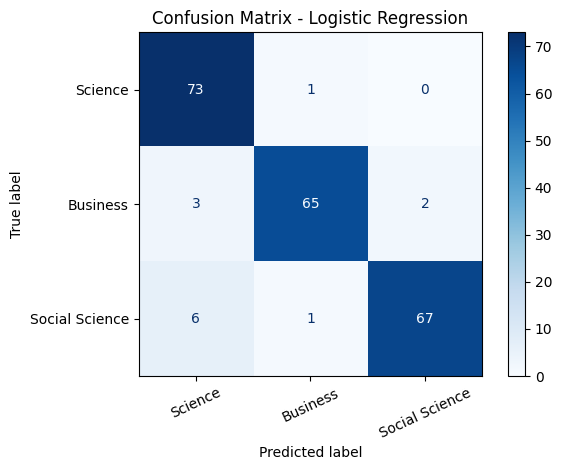


Decision Tree
                precision    recall  f1-score   support

       Science       0.88      0.91      0.89        74
      Business       0.92      0.97      0.94        70
Social Science       0.96      0.88      0.92        74

      accuracy                           0.92       218
     macro avg       0.92      0.92      0.92       218
  weighted avg       0.92      0.92      0.92       218



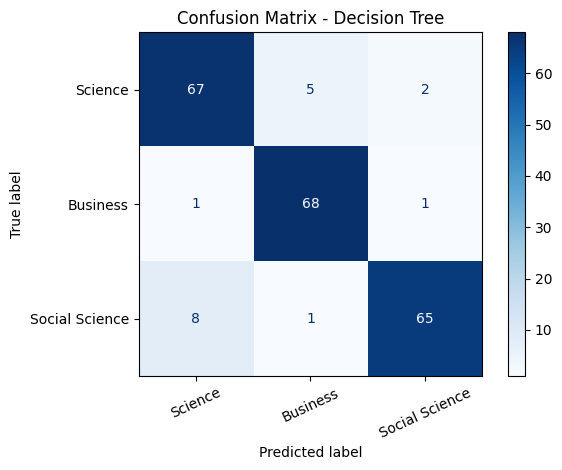


Naive Bayes
                precision    recall  f1-score   support

       Science       0.95      0.97      0.96        74
      Business       0.96      0.96      0.96        70
Social Science       0.99      0.96      0.97        74

      accuracy                           0.96       218
     macro avg       0.96      0.96      0.96       218
  weighted avg       0.96      0.96      0.96       218



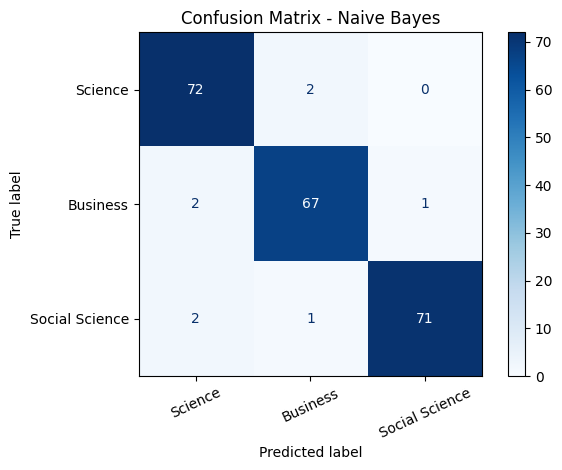


kNN
                precision    recall  f1-score   support

       Science       0.92      0.96      0.94        74
      Business       0.93      0.93      0.93        70
Social Science       0.94      0.91      0.92        74

      accuracy                           0.93       218
     macro avg       0.93      0.93      0.93       218
  weighted avg       0.93      0.93      0.93       218



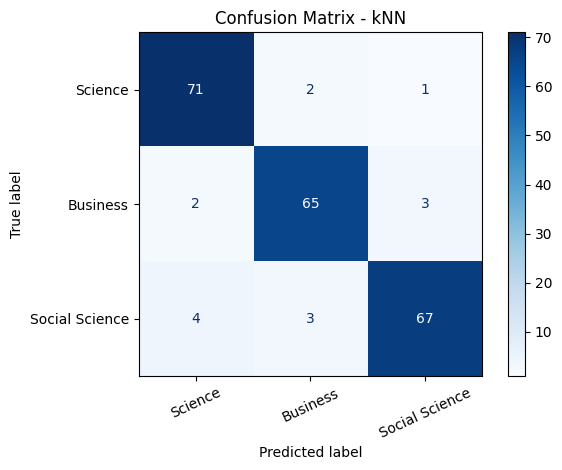


SVM
                precision    recall  f1-score   support

       Science       0.90      0.97      0.94        74
      Business       0.96      0.94      0.95        70
Social Science       0.99      0.92      0.95        74

      accuracy                           0.94       218
     macro avg       0.95      0.94      0.95       218
  weighted avg       0.95      0.94      0.95       218



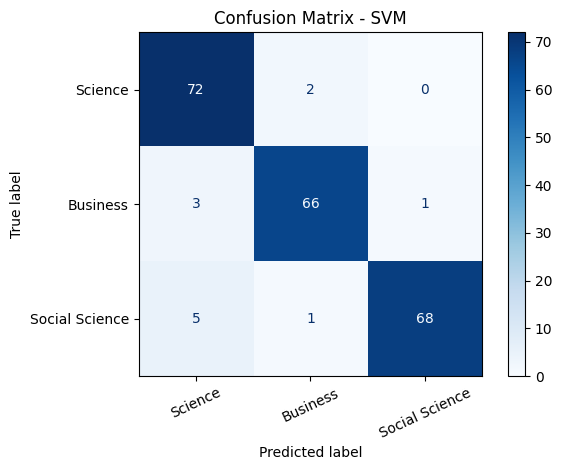


Random Forest
                precision    recall  f1-score   support

       Science       0.97      0.97      0.97        74
      Business       0.97      0.99      0.98        70
Social Science       0.97      0.96      0.97        74

      accuracy                           0.97       218
     macro avg       0.97      0.97      0.97       218
  weighted avg       0.97      0.97      0.97       218



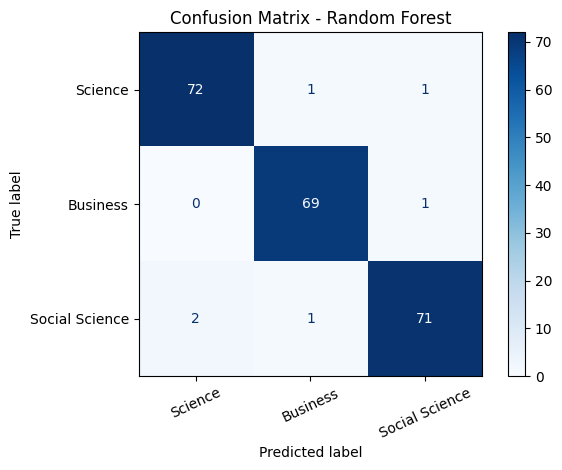

In [22]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Show detailed evaluation for every model
for name, model in trained_models.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    y_pred = model.predict(X_test_tfidf)

    print(classification_report(
        y_test,
        y_pred,
        labels=["Science", "Business", "Social Science"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["Science", "Business", "Social Science"],
        display_labels=["Science", "Business", "Social Science"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()


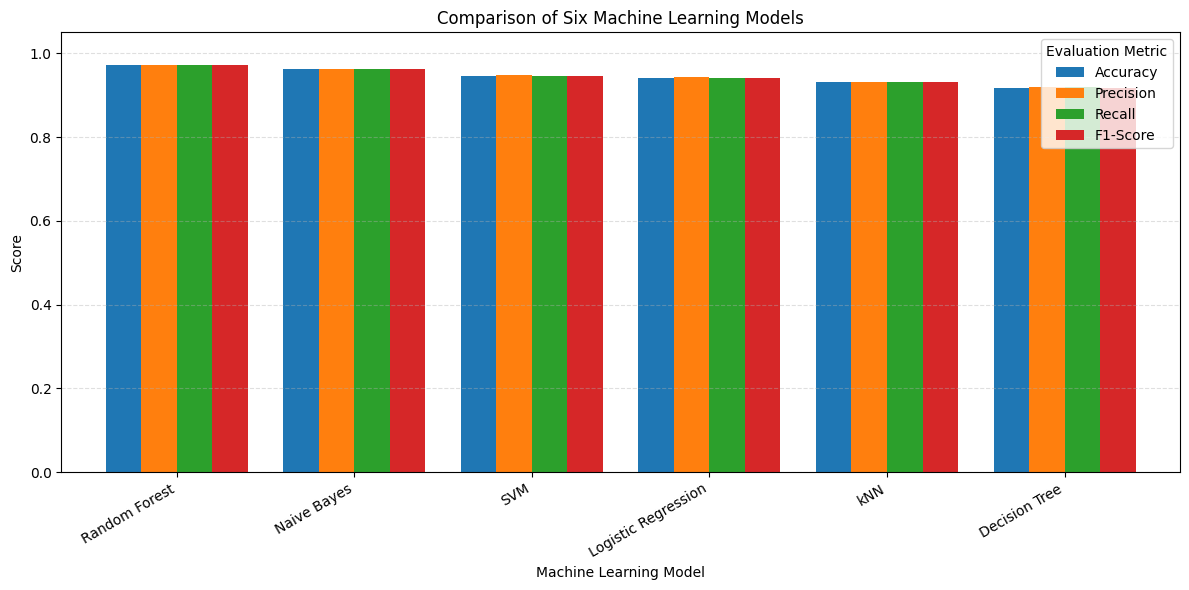

In [24]:

import matplotlib.pyplot as plt

# Use the model comparison results already calculated
plot_df = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Comparison of Six Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
# Save the figure
plt.savefig("../results/model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


In [25]:

# Demo: Predict the category of a new research abstract

def predict_category(abstract_text):
    if not abstract_text or not abstract_text.strip():
        print("Please enter a research abstract.")
        return

    # Convert the input abstract using the existing TF-IDF vectorizer
    abstract_tfidf = tfidf.transform([abstract_text])

    # Use the best-performing model from our comparison
    best_model = trained_models["Random Forest"]

    # Predict the category
    prediction = best_model.predict(abstract_tfidf)[0]

    print("Predicted Category:", prediction)


# Try the demo with an example
sample_abstract = """
This study examines the relationship between corporate governance,
financial performance, and investment decisions in public companies.
The analysis uses financial data to investigate business outcomes.
"""

predict_category(sample_abstract)


Predicted Category: Business


In [26]:

import joblib

joblib.dump(best_model, "../models/best_research_classifier.pkl")

joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Random Forest model saved successfully.")
print("TF-IDF vectorizer saved successfully.")


Random Forest model saved successfully.
TF-IDF vectorizer saved successfully.


In [27]:

# Save model evaluation results
results_df.to_csv("../results/model_comparison_results.csv", index=False)
# Save the final cleaned dataset
df_clean.to_csv("../data/cleaned_research_abstracts.csv", index=False)

# Save the classification report for the best model
from sklearn.metrics import classification_report

best_model = trained_models["Random Forest"]
best_predictions = best_model.predict(X_test_tfidf)

report = classification_report(
    y_test,
    best_predictions,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
report_df.to_csv("../results/random_forest_classification_report.csv")

print("All result files saved successfully.")


All result files saved successfully.


In [28]:

import os

required_files = [
    "../data/cleaned_research_abstracts.csv",
    "../data/flagged_records_for_review.csv",
    "../results/model_comparison.png",
    "../results/model_comparison_results.csv",
    "../results/random_forest_classification_report.csv",
    "../models/best_research_classifier.pkl",
    "../models/tfidf_vectorizer.pkl"
]

for filename in required_files:
    if os.path.exists(filename):
        print("FOUND:", filename)
    else:
        print("MISSING:", filename)


FOUND: cleaned_research_abstracts.csv
FOUND: flagged_records_for_review.csv
FOUND: model_comparison.png
FOUND: model_comparison_results.csv
FOUND: random_forest_classification_report.csv
FOUND: best_research_classifier.pkl
FOUND: tfidf_vectorizer.pkl


In [29]:

readme_content = """
# Research Abstract Classification Using Machine Learning

## 1. Project Overview
This project classifies research abstracts into three categories:
- Science
- Business
- Social Science

The project uses Natural Language Processing (NLP), TF-IDF
feature extraction, and six machine learning classification models.

## 2. Dataset
- Original records collected: 1,200
- Records flagged and provisionally excluded: 110
- Remaining records: 1,090
- Science: 371
- Social Science: 367
- Business: 352

The records were collected using the OpenAlex API. Keyword-based
filtering was used to flag possible non-research records. The
remaining records have not all been manually verified.

## 3. NLP and Feature Extraction
TF-IDF converts the text abstracts into numerical features.
The vectorizer uses:
- Maximum features: 10,000
- English stop-word removal
- Unigrams and bigrams
- Minimum document frequency: 2

## 4. Train-Test Split
- Training set: 80%
- Testing set: 20%
- Random state: 42
- Stratified split

## 5. Machine Learning Models
The following models were trained:
1. Logistic Regression
2. Decision Tree
3. Multinomial Naive Bayes
4. k-Nearest Neighbors (kNN)
5. Support Vector Machine (SVM)
6. Random Forest

## 6. Evaluation Metrics
Models were compared using:
- Accuracy
- Macro precision
- Macro recall
- Macro F1-score
- Classification reports
- Confusion matrices

Random Forest achieved the highest observed test accuracy
(97.25%) and macro F1-score (97.26%) in the current experiment.

## 7. Prediction Demo
The notebook contains a function called `predict_category()`.
It accepts a research abstract and predicts one of the three categories.

## 8. Saved Files

- data/cleaned_research_abstracts.csv
- data/flagged_records_for_review.csv
- results/model_comparison.png
- results/model_comparison_results.csv
- results/random_forest_classification_report.csv
- models/best_research_classifier.pkl
- models/tfidf_vectorizer.pkl

## 9. How to Run
1. Open the Jupyter Notebook.
2. Run the cells from top to bottom.
3. Ensure the required Python libraries are installed.
4. Use `predict_category("Your abstract text here")` to test a new abstract.

## 10. Limitations
The dataset was collected through category-specific searches, which may
make the categories easier to distinguish. Keyword-based filtering is
provisional, and the remaining records have not all been manually
verified as peer-reviewed publications. The reported scores come from
a single train-test split and may not represent performance on a fully
independent dataset.
"""

with open("../README.md", "w", encoding="utf-8") as file:
    file.write(readme_content.strip())

print("README.md created successfully!")


README.md created successfully!


In [30]:

app_code = r'''
import streamlit as st
import joblib
from pathlib import Path

# Page configuration
st.set_page_config(
    page_title="Research Abstract Classifier",
    page_icon="📚",
    layout="centered"
)

# Load the saved model and TF-IDF vectorizer
BASE_DIR = Path(__file__).parent

@st.cache_resource
def load_artifacts():
    model = joblib.load(BASE_DIR / "models" / "best_research_classifier.pkl")
    vectorizer = joblib.load(BASE_DIR / "models" / "tfidf_vectorizer.pkl")
    return model, vectorizer

model, vectorizer = load_artifacts()

# Application interface
st.title("📚 Research Abstract Classifier")
st.write(
    "Classify a research abstract into Science, Business, "
    "or Social Science using machine learning."
)

abstract_text = st.text_area(
    "Paste your research abstract below:",
    height=220,
    placeholder="Enter or paste the abstract here..."
)

if st.button("Predict Category", type="primary"):
    if not abstract_text.strip():
        st.warning("Please enter an abstract first.")
    else:
        features = vectorizer.transform([abstract_text])
        prediction = model.predict(features)[0]

        st.success(f"Predicted Category: {prediction}")

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(features)[0]

            st.subheader("Model prediction scores")
            for category, probability in zip(
                model.classes_, probabilities
            ):
                st.write(f"**{category}:** {probability:.1%}")
                st.progress(float(probability))

st.divider()
st.caption(
    "Academic project — predictions depend on the training data "
    "and should be reviewed rather than treated as definitive."
)
'''

with open("../app.py", "w", encoding="utf-8") as file:
    file.write(app_code.strip() + "\n")

print("app.py created successfully!")


app.py created successfully!


In [31]:

import sklearn

requirements = f"""streamlit
scikit-learn=={sklearn.__version__}
joblib
"""

with open("../requirements.txt", "w", encoding="utf-8") as file:
    file.write(requirements)

print("requirements.txt created successfully!")
print("\nInstalled scikit-learn version:", sklearn.__version__)
print("\nRequirements:")
print(requirements)


requirements.txt created successfully!

Installed scikit-learn version: 1.9.0

Requirements:
streamlit
scikit-learn==1.9.0
joblib



In [32]:
import os

for filename in [
    "../app.py",
    "../requirements.txt",
    "../models/best_research_classifier.pkl",
    "../models/tfidf_vectorizer.pkl"
]:
    print(
        "FOUND:" if os.path.exists(filename) else "MISSING:",
        filename
    )

FOUND: app.py
FOUND: requirements.txt
FOUND: best_research_classifier.pkl
FOUND: tfidf_vectorizer.pkl
